In [1]:
from datetime import datetime
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm

In [2]:
point = 'p102'
data_pcs = pd.read_csv("outputs/pca/pcs_msl_sel_6h.csv", index_col=0, parse_dates=True)
waves_df_z = pd.read_csv(f"outputs/marginal/z_bulk_{point}.csv", index_col=0, parse_dates=True)   # PIT + armónica (00_PIT)
horas_6h = [0, 6, 12, 18]
waves_df_z_6h = waves_df_z.rolling("6h", center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin(horas_6h)].dropna()

In [6]:
mod_waves = sm.tsa.MarkovAutoregression(
    waves_df_z_6h['VHM0'].values, k_regimes=2, order=4, switching_ar=True
)

In [7]:
results = mod_waves.fit()

In [8]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                         Markov Switching Model Results                         
================================================================================
Dep. Variable:                        y   No. Observations:                60988
Model:             MarkovAutoregression   Log Likelihood              -18019.020
Date:                  Tue, 24 Nov 2026   AIC                          36064.040
Time:                          19:15:34   BIC                          36181.279
Sample:                               0   HQIC                         36100.428
                                - 60988                                         
Covariance Type:                 approx                                         
                             Regime 0 parameters                              
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4593      0.020     22.776      0.000       0.420       0.499
ar.L1          1.8793      0.039     48.633      0.000       1.804       1.955
ar.L2         -2.1832      0.075    -29.140      0.000      -2.330      -2.036
ar.L3          1.8499      0.085     21.710      0.000       1.683       2.017
ar.L4         -0.8650      0.045    -19.405      0.000      -0.952      -0.778
                             Regime 1 parameters                              
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0436      0.018      2.489      0.013       0.009       0.078
ar.L1          1.5090      0.005    283.726      0.000       1.499       1.519
ar.L2         -0.8472      0.010    -89.173      0.000      -0.866      -0.829
ar.L3          0.3814      0.009     41.767      0.000       0.363       0.399
ar.L4         -0.1202      0.005    -25.414      0.000      -0.129      -0.111
                           Non-switching parameters                           
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0818      0.001    115.679      0.000       0.080       0.083
                         Regime transition parameters                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
p[0->0]        0.3733      0.024     15.472      0.000       0.326       0.421
p[1->0]        0.0415      0.002     23.668      0.000       0.038       0.045
==============================================================================

Warnings:
[1] Covariance matrix calculated using numerical (complex-step) differentiation.
"""

(0.0, 1460.0)

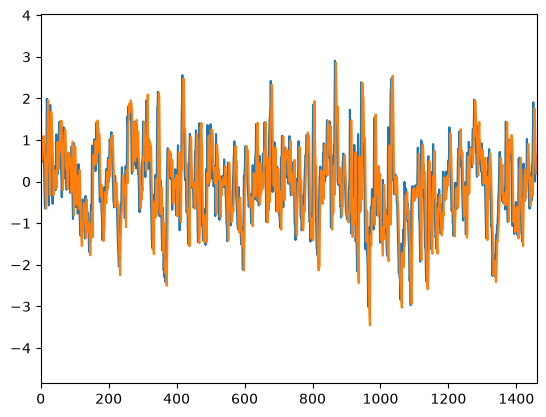

In [12]:
plt.plot(results.fittedvalues)
plt.plot(waves_df_z_6h['VHM0'].values)

plt.xlim(0,365*4)

In [16]:
res_waves = results

IN-SAMPLE PERFORMANCE
RMSE: 0.2641
MAE:  0.2090
Bias: -0.0129
R²:   0.9281


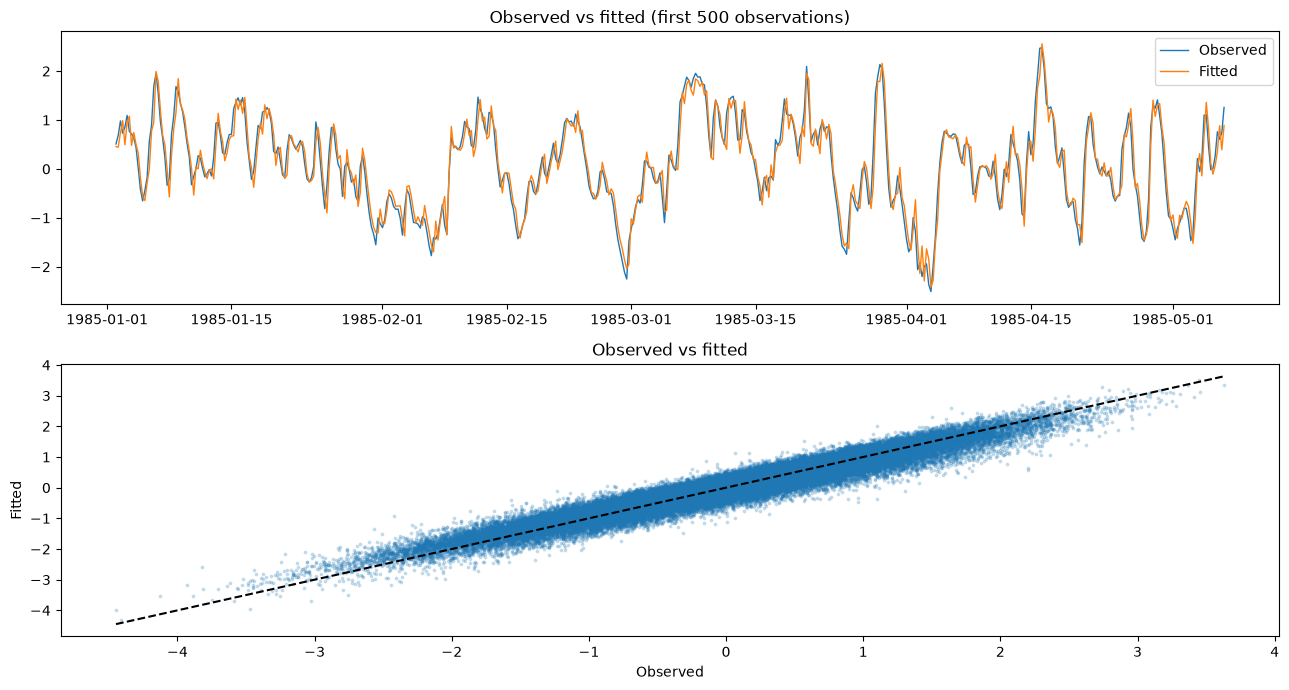

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import skew, kurtosis

y = waves_df_z_6h['VHM0'].dropna()
fitted = pd.Series(
    np.asarray(res_waves.fittedvalues).ravel(),
    index=y.index[-len(res_waves.fittedvalues):]
)

# Align observations and fitted values
df = pd.concat(
    [y.rename('observed'), fitted.rename('fitted')],
    axis=1
).dropna()

df['residual'] = df['observed'] - df['fitted']

rmse = np.sqrt(mean_squared_error(df.observed, df.fitted))
mae = mean_absolute_error(df.observed, df.fitted)
bias = df.residual.mean()
r2 = 1 - np.sum(df.residual**2) / np.sum(
    (df.observed - df.observed.mean())**2
)

print('IN-SAMPLE PERFORMANCE')
print(f'RMSE: {rmse:.4f}')
print(f'MAE:  {mae:.4f}')
print(f'Bias: {bias:.4f}')
print(f'R²:   {r2:.4f}')

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

# A representative period
n = 500
axes[0].plot(df.index[:n], df.observed.iloc[:n],
             label='Observed', lw=1)
axes[0].plot(df.index[:n], df.fitted.iloc[:n],
             label='Fitted', lw=1)
axes[0].legend()
axes[0].set_title('Observed vs fitted (first 500 observations)')

axes[1].scatter(df.observed, df.fitted, s=3, alpha=0.2)
lims = [
    min(df.observed.min(), df.fitted.min()),
    max(df.observed.max(), df.fitted.max())
]
axes[1].plot(lims, lims, 'k--')
axes[1].set_xlabel('Observed')
axes[1].set_ylabel('Fitted')
axes[1].set_title('Observed vs fitted')

plt.tight_layout()
plt.show()


RESIDUAL DISTRIBUTION
Mean:     -0.0129
Std:      0.2638
Skewness: 0.4595
Kurtosis: 0.5847 (excess)

JARQUE-BERA
SignificanceResult(statistic=np.float64(3014.472854386987), pvalue=np.float64(0.0))

LJUNG-BOX: RESIDUALS
        lb_stat      lb_pvalue
4    588.236903  5.444724e-126
8    691.476734  4.893282e-144
12   762.538563  1.776440e-155
24   990.220549  1.063268e-193
48  1307.252867  3.085074e-242
96  1934.278661   0.000000e+00

LJUNG-BOX: SQUARED RESIDUALS
       lb_stat      lb_pvalue
4   273.186111   6.561243e-58
8   406.240047   8.662266e-83
12  484.838878   3.726012e-96
24  547.723937  1.961945e-100
48  668.876641  2.709561e-110
96  784.159099  1.791510e-108

ARCH TEST
(np.float64(420.56237589409443), np.float64(4.455582018548737e-74), 17.637922202602493, 2.338048373698222e-74)


/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


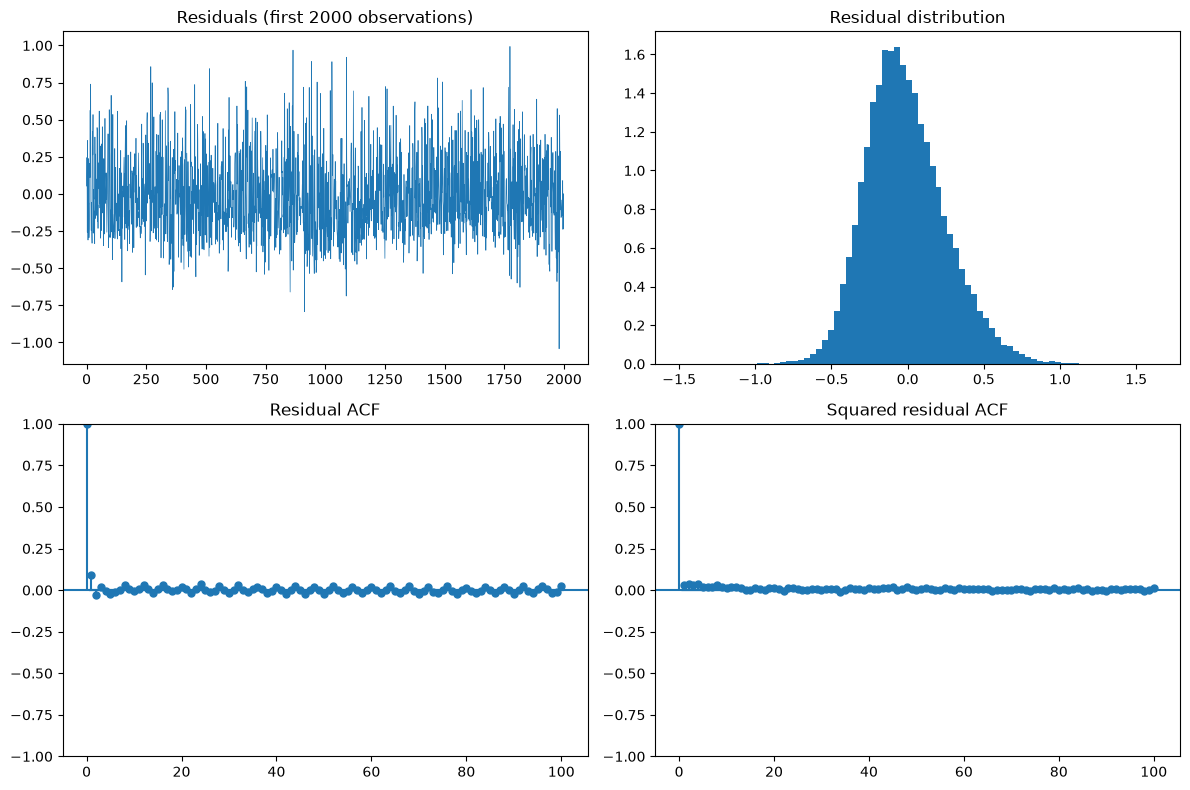

In [18]:

from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import jarque_bera

e = df.residual

# Residual distribution
print('RESIDUAL DISTRIBUTION')
print(f'Mean:     {e.mean():.4f}')
print(f'Std:      {e.std():.4f}')
print(f'Skewness: {skew(e):.4f}')
print(f'Kurtosis: {kurtosis(e):.4f} (excess)')

print('\nJARQUE-BERA')
print(jarque_bera(e))

# Residual autocorrelation
print('\nLJUNG-BOX: RESIDUALS')
print(acorr_ljungbox(e, lags=[4, 8, 12, 24, 48, 96],
                     return_df=True))

print('\nLJUNG-BOX: SQUARED RESIDUALS')
print(acorr_ljungbox(e**2, lags=[4, 8, 12, 24, 48, 96],
                     return_df=True))

# ARCH effects
print('\nARCH TEST')
print(het_arch(e, nlags=24))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(e.values[:2000], lw=0.5)
axes[0, 0].set_title('Residuals (first 2000 observations)')

axes[0, 1].hist(e, bins=80, density=True)
axes[0, 1].set_title('Residual distribution')

plot_acf(e, lags=100, ax=axes[1, 0])
axes[1, 0].set_title('Residual ACF')

plot_acf(e**2, lags=100, ax=axes[1, 1])
axes[1, 1].set_title('Squared residual ACF')

plt.tight_layout()
plt.show()


REGIME OCCUPANCY

Regime 0
Occupancy: 6.210%
Mean VHM0: 0.4433
Std VHM0: 0.9770
P90: 1.9256
P99: 2.6089

Regime 1
Occupancy: 93.790%
Mean VHM0: -0.0301
Std VHM0: 0.9783
P90: 1.1878
P99: 2.1400

HARD CLASSIFICATION
0    0.037516
1    0.962484
Name: proportion, dtype: float64

Number of regime switches: 3632
Switches per year: 87.0


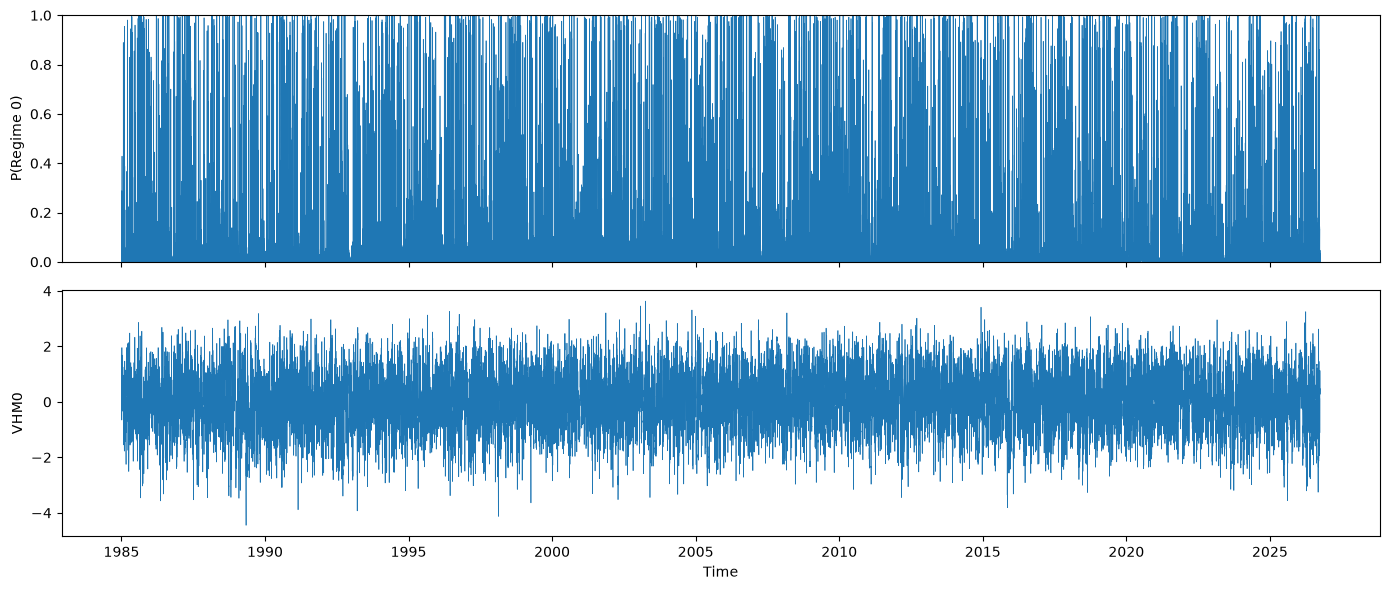

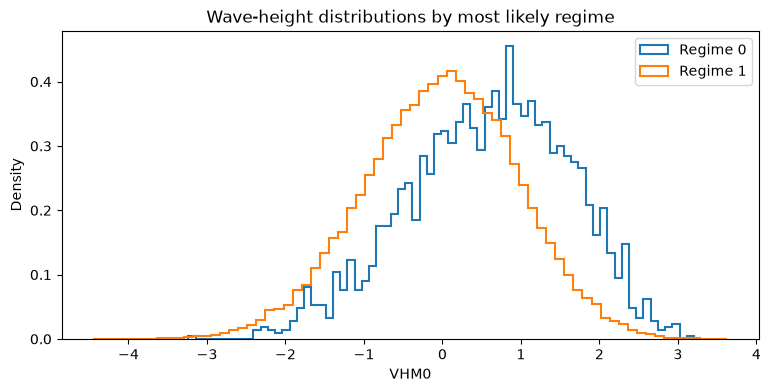

In [19]:

# Smoothed regime probabilities
prob = res_waves.smoothed_marginal_probabilities
prob = np.asarray(prob)

# Align with the original observations
yr = y.iloc[-len(prob):].values

print('REGIME OCCUPANCY')
for k in range(prob.shape[1]):
    pk = prob[:, k]
    print(f'\nRegime {k}')
    print(f'Occupancy: {pk.mean():.3%}')
    print(f'Mean VHM0: {np.average(yr, weights=pk):.4f}')
    print(f'Std VHM0: {np.sqrt(np.average((yr-np.average(yr, weights=pk))**2, weights=pk)):.4f}')
    print(f'P90: {np.quantile(yr[pk > 0.8], 0.90):.4f}')
    print(f'P99: {np.quantile(yr[pk > 0.8], 0.99):.4f}')

# Hard classification
regime = prob.argmax(axis=1)

print('\nHARD CLASSIFICATION')
print(pd.Series(regime).value_counts(normalize=True).sort_index())

# Switching frequency
switches = np.sum(np.diff(regime) != 0)
print(f'\nNumber of regime switches: {switches}')
print(f'Switches per year: {switches / (len(regime)/ (365.25*4)):.1f}')

# Plot probabilities
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

time = y.index[-len(prob):]

axes[0].plot(time, prob[:, 0], lw=0.5)
axes[0].set_ylabel('P(Regime 0)')
axes[0].set_ylim(0, 1)

axes[1].plot(time, yr, lw=0.5)
axes[1].set_ylabel('VHM0')
axes[1].set_xlabel('Time')

plt.tight_layout()
plt.show()

# Conditional distributions
fig, ax = plt.subplots(figsize=(9, 4))

for k in range(prob.shape[1]):
    ax.hist(
        yr[regime == k],
        bins=70,
        density=True,
        histtype='step',
        linewidth=1.5,
        label=f'Regime {k}'
    )

ax.set_xlabel('VHM0')
ax.set_ylabel('Density')
ax.legend()
ax.set_title('Wave-height distributions by most likely regime')
plt.show()


In [20]:

from statsmodels.tsa.ar_model import AutoReg

y = waves_df_z_6h['VHM0'].dropna()

split = int(len(y) * 0.8)

train = y.iloc[:split]
test = y.iloc[split:]

print(f'Train: {len(train)} observations')
print(f'Test:  {len(test)} observations')

# ---------------------------------------
# 1. Markov-switching AR(4)
# ---------------------------------------

mod_train = sm.tsa.MarkovAutoregression(
    train.values,
    k_regimes=2,
    order=4,
    switching_ar=True
)

res_train = mod_train.fit(
    disp=False,
    maxiter=200
)

pred_ms = np.asarray(
    res_train.forecast(steps=len(test))
).ravel()

# ---------------------------------------
# 2. Standard AR(4)
# ---------------------------------------

ar_model = AutoReg(
    train,
    lags=4,
    trend='c',
    old_names=False
).fit()

pred_ar = np.asarray(
    ar_model.forecast(steps=len(test))
)

# ---------------------------------------
# 3. Evaluation
# ---------------------------------------

def metrics(obs, pred):
    return {
        'RMSE': np.sqrt(mean_squared_error(obs, pred)),
        'MAE': mean_absolute_error(obs, pred),
        'Bias': np.mean(pred - obs),
        'Correlation': np.corrcoef(obs, pred)[0, 1]
    }

results = pd.DataFrame({
    'Markov AR(4)': metrics(test.values, pred_ms),
    'Standard AR(4)': metrics(test.values, pred_ar)
}).T

print(results)

# ---------------------------------------
# 4. Plot
# ---------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# First 500 test observations
n = 500

axes[0].plot(test.index[:n], test.values[:n],
             label='Observed', lw=1)
axes[0].plot(test.index[:n], pred_ms[:n],
             label='Markov AR(4)', lw=1)
axes[0].plot(test.index[:n], pred_ar[:n],
             label='Standard AR(4)', lw=1, alpha=0.8)

axes[0].legend()
axes[0].set_title('Out-of-sample predictions')

# Scatter plot
axes[1].scatter(test, pred_ms, s=3, alpha=0.2,
                label='Markov AR(4)')
axes[1].scatter(test, pred_ar, s=3, alpha=0.2,
                label='Standard AR(4)')

axes[1].set_xlabel('Observed')
axes[1].set_ylabel('Predicted')
axes[1].legend()

plt.tight_layout()
plt.show()


Train: 48793 observations
Test:  12199 observations


NotImplementedError: 

In [ ]:

# Compare alternative probability assumptions
predictions = {}

for method in ['predicted', 'filtered', 'smoothed']:
    predictions[method] = np.asarray(
        res_waves.predict(probabilities=method)
    ).ravel()

# Align lengths
n = min(len(predictions['predicted']), len(y))

comparison = pd.DataFrame({
    'observed': y.values[-n:],
    **{k: v[-n:] for k, v in predictions.items()}
})

print('PREDICTION COMPARISON')
for method in predictions:
    p = comparison[method]
    obs = comparison['observed']

    print(
        f'{method:12s} | '
        f'RMSE: {np.sqrt(mean_squared_error(obs, p)):.4f} | '
        f'R²: {1 - np.sum((obs-p)**2)/np.sum((obs-obs.mean())**2):.4f}'
    )

fig, ax = plt.subplots(figsize=(13, 4))

nplot = 500

ax.plot(comparison.observed.values[:nplot],
        label='Observed', lw=1)

for method in predictions:
    ax.plot(comparison[method].values[:nplot],
            label=method, lw=1)

ax.legend()
ax.set_title('Predictions under different regime probability assumptions')
plt.show()
